Dataset Loaded Successfully!
Shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.1412

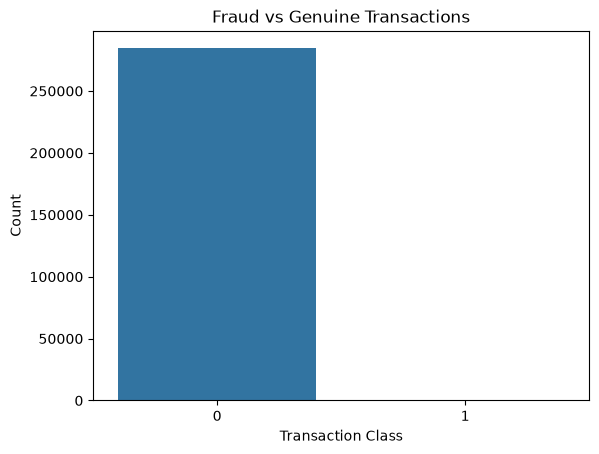

Cleaned Dataset Shape: (283726, 31)


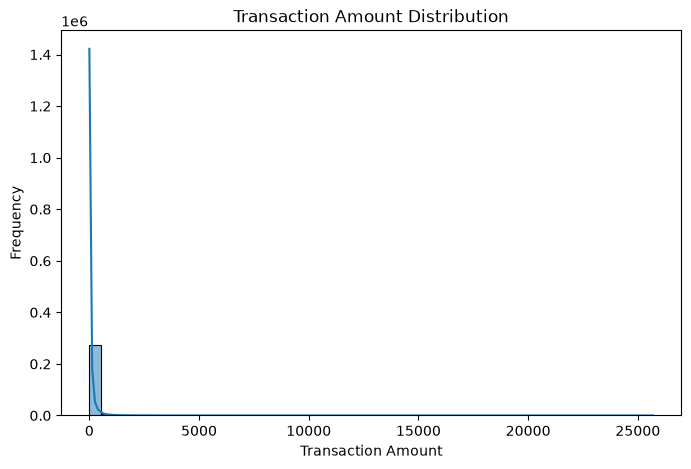

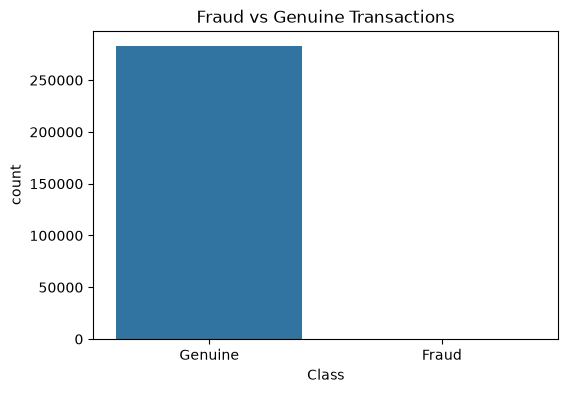

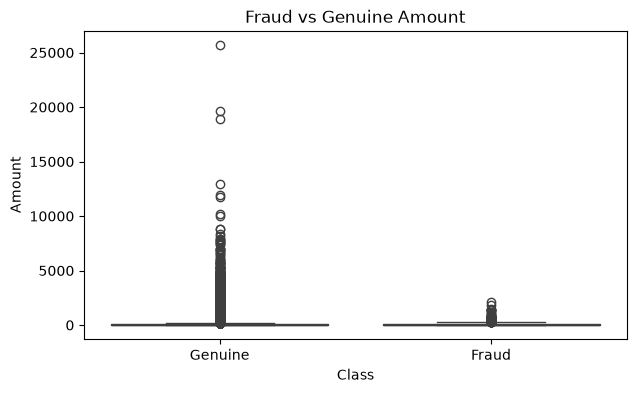

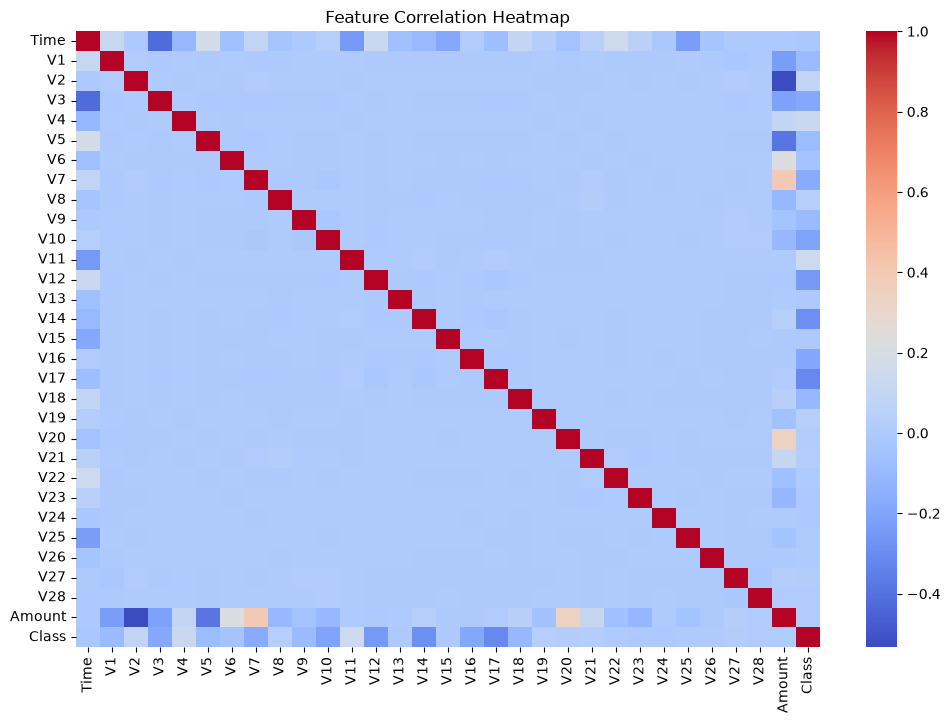

Features: (283726, 30)
Target: (283726,)
Training Data: (226980, 30)
Testing Data: (56746, 30)
Feature Scaling Completed!
Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64
Training Shape: (453204, 30)
Testing Shape: (56746, 30)
Preprocessing Completed!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/creditcard.csv")

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)
print(df.head())
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())
print(df['Class'].value_counts())

print("\nFraud Percentage:")
print(df['Class'].value_counts(normalize=True)*100)
sns.countplot(x='Class', data=df)
plt.title("Fraud vs Genuine Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Count")
plt.show()
df = df.drop_duplicates()

print("Cleaned Dataset Shape:", df.shape)
plt.figure(figsize=(8,5))
sns.histplot(df['Amount'], bins=50, kde=True)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()
plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title("Fraud vs Genuine Transactions")
plt.xticks([0,1], ['Genuine','Fraud'])
plt.show()
plt.figure(figsize=(7,4))
sns.boxplot(x='Class', y='Amount', data=df)
plt.title("Fraud vs Genuine Amount")
plt.xticks([0,1], ['Genuine','Fraud'])
plt.show()
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()
X = df.drop('Class', axis=1)
y = df['Class']

print("Features:", X.shape)
print("Target:", y.shape)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train['Amount'] = scaler.fit_transform(X_train[['Amount']])
X_test['Amount'] = scaler.transform(X_test[['Amount']])

print("Feature Scaling Completed!")
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_bal.value_counts())
print("Training Shape:", X_train_bal.shape)
print("Testing Shape:", X_test.shape)
print("Preprocessing Completed!")


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=12,
        random_state=42, n_jobs=-1
    )
}

print("ML Models Initialized Successfully!")

ML Models Initialized Successfully!


In [5]:
results = []

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train_bal, y_train_bal)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred)
    })

print("Training Completed!")

Training: Logistic Regression


c:\Users\Dell\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training: Decision Tree
Training: Random Forest
Training Completed!


In [6]:
results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.990466   0.133224  0.852632  0.230441
1        Decision Tree  0.994414   0.198370  0.768421  0.315335
2        Random Forest  0.999189   0.737864  0.800000  0.767677


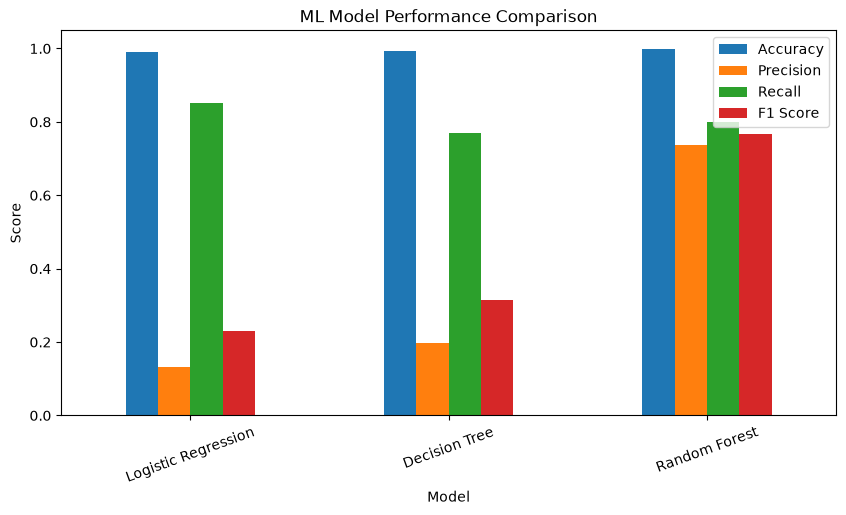

In [7]:
results_df.set_index("Model").plot(
    kind="bar", figsize=(10,5)
)

plt.title("ML Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.show()

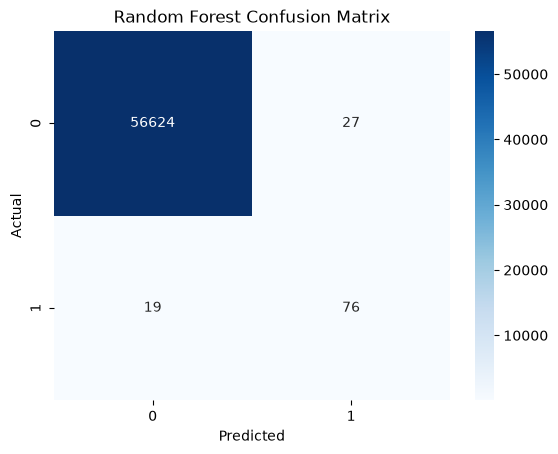

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.74      0.80      0.77        95

    accuracy                           1.00     56746
   macro avg       0.87      0.90      0.88     56746
weighted avg       1.00      1.00      1.00     56746



In [8]:
rf_pred = models["Random Forest"].predict(X_test)

sns.heatmap(
    confusion_matrix(y_test, rf_pred),
    annot=True, fmt="d", cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, rf_pred))

In [9]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(models["Random Forest"], "../models/fraud_model.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

print("FraudShield AI Model Saved!")

FraudShield AI Model Saved!


In [10]:
rf_model = models["Random Forest"]

predictions = rf_model.predict(X_test)
probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Fraud Predictions Generated!")
print("Total Predictions:", len(predictions))

Fraud Predictions Generated!
Total Predictions: 56746


In [11]:
risk_score = probabilities * 100

def get_status(score):
    if score >= 70:
        return "High Risk"
    elif score >= 30:
        return "Medium Risk"
    else:
        return "Low Risk"

status = [get_status(s) for s in risk_score]

print("Risk Scores Generated!")

Risk Scores Generated!


In [12]:
report = X_test.copy()

report["Transaction_ID"] = X_test.index
report["Amount"] = scaler.inverse_transform(
    X_test[["Amount"]]
).ravel()

report["Actual_Class"] = y_test
report["Predicted_Class"] = predictions
report["Fraud_Risk_Score"] = risk_score
report["Risk_Status"] = status

report["Prediction"] = report["Predicted_Class"].map({
    0: "Genuine",
    1: "Fraud"
})

print(report.head())

            Time        V1        V2        V3        V4        V5        V6  \
86568    61290.0  1.228821 -0.063408  0.274145  0.647465 -0.048135  0.372073   
251557  155394.0 -0.203154  1.176678 -0.759595 -0.518472  0.629649 -0.721675   
20232    30881.0 -1.672836  1.401297  1.503940  2.175491  0.699791  1.062139   
68952    53203.0  0.819379 -1.124913  0.515025  0.513945 -1.009048  0.488484   
191852  129429.0  2.009701  0.105635 -1.752759  0.588312  0.374801 -0.637884   

              V7        V8        V9  ...       V26       V27       V28  \
86568  -0.224231  0.079939  0.640759  ...  0.491409  0.002989  0.001782   
251557  0.638893  0.243377 -0.157488  ... -0.234510  0.379640  0.261351   
20232   1.114364 -0.535822 -0.252983  ... -0.062383  0.007777  0.113900   
68952  -0.580672  0.187686 -0.999142  ... -0.289454  0.038214  0.058407   
191852  0.009260 -0.129487  0.492619  ...  0.642944 -0.036998 -0.043404   

        Amount  Transaction_ID  Actual_Class  Predicted_Class  \
865

In [13]:
import os

os.makedirs("../output", exist_ok=True)

report.to_csv(
    "../output/fraud_predictions.csv",
    index=False
)

print("Fraud Report Exported Successfully!")

Fraud Report Exported Successfully!


In [14]:
results_df.to_csv(
    "../output/model_comparison.csv",
    index=False
)

print("Model Comparison Exported Successfully!")
print(results_df)

Model Comparison Exported Successfully!
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.990466   0.133224  0.852632  0.230441
1        Decision Tree  0.994414   0.198370  0.768421  0.315335
2        Random Forest  0.999189   0.737864  0.800000  0.767677


In [15]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

results = []

for name, model in models.items():
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.990466   0.133224  0.852632  0.230441
1        Decision Tree  0.994414   0.198370  0.768421  0.315335
2        Random Forest  0.999189   0.737864  0.800000  0.767677
